<a href="https://colab.research.google.com/github/profrash-tech/biometrics-hub-notebooks/blob/main/NB2_EDA_and_Statistical_Reasoning_STUDENT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 2 · Exploratory Data Analysis and Statistical Reasoning

**About 300 minutes** · Course: *Data Science and Machine Learning with a Framingham teaching dataset*

*Prerequisite: Notebook 1. This notebook uses the whole file for exploration; that is acceptable because we describe the data. From Notebook 3, model decisions use training data only.*

### 🎯 Learning objectives
After this notebook you will be able to:
- describe distributions with histograms and box plots
- choose a chart for number/number, number/category and category/category
- compute and read Pearson and Spearman correlations and a heat map
- run and interpret Welch t, Mann-Whitney, chi-square, ANOVA and Kruskal-Wallis tests
- report effect sizes and confidence intervals next to p-values
- explain multiple testing and apply Bonferroni and Benjamini-Hochberg
- separate a descriptive pattern from statistical evidence, and both from causation

### ❓ Research questions addressed here
- **RQ2.** How are age, BMI, cholesterol, glucose and blood pressure distributed?
- **RQ3.** How does smoking status relate to selected cardiovascular risk indicators?
- **RQ4.** How do characteristics differ between individuals with and without recorded CHD?
- **RQ5.** Which variables have notable correlations or associations?
- **RQ6.** Are there statistically detectable differences in systolic blood pressure between selected groups?
- **RQ7.** Is age associated with systolic blood pressure?
- **RQ8.** Are smoking status and CHD status statistically associated?
- **RQ9.** Which findings are meaningful in terms of effect size, not merely statistical significance?

### 🧭 How to use this notebook
- Run cells from **top to bottom** with **Shift + Enter**. Do not skip cells.
- Each new idea gets its own short cell: **first** a plain-language explanation, **then** the code, **then** a
  line-by-line walk-through of what each line does. Read all three before moving on.
- Every part follows the same seven-step rhythm:
  **📘 LEARN** (idea) → **▶️ SEE** (worked code) → **✏️ TRY** (you code) → **🔍 ANALYZE** (inspect results) →
  **💬 INTERPRET** (connect to the research question) → **✅ CHECK** (test yourself) → **🔬 RESEARCH** (go further).
- Cells marked `# TODO` are for you. Replace the placeholder (`None`) with your own code.
  Unfinished cells still run, so the notebook never stops because of a blank.
- Written answers go between the triple quotes of the `answer_...` variable. Knowledge-check answers are a
  single letter.
- After each exercise there is a one-line **🎯 check** cell. Run it to see ✅ or ❌ and a hint. It never shows
  the answer and never stops the notebook. The **📊 progress** cell near the end adds everything up.
- Exercises are self-contained: they use only objects created in the guided cells above them, never your own
  answers from other exercises.
- Solutions are **not** in this notebook. Your instructor decides when to release them.

**🎯 Course checker.** Click ▶ once on the next cell. It loads the small helper that tells you whether each exercise is right (✅ or ❌) and keeps a progress count. There is nothing to read or change in it. If you are offline, the notebook still works; only the feedback is unavailable.

In [4]:
#@title ⚙️ Course checker: click ▶ once, nothing to read here { display-mode: "form" }
import os, urllib.request
CHECKER_URL = "https://raw.githubusercontent.com/festusoladayoonline-debug/biometrics-hub-checker/main/hub_check.py"
try:                                    # get the newest checker; use the local copy if offline
    _data = urllib.request.urlopen(CHECKER_URL, timeout=10).read()
    open("hub_check.py", "wb").write(_data)
except Exception:
    pass
try:
    from hub_check import check, progress
    print("Course checker ready.")
except Exception:                       # the notebook still works without feedback
    def check(ex): print("Checker not available (offline?). Your notebook still works; ask your teacher.")
    def progress(n=None): print("Checker not available.")
    print("Course checker could not be loaded.")

Course checker ready.


### ⚠️ Read this before analysing anything
- The data file is a **commonly circulated teaching subset** associated with the Framingham Heart Study. It is
  **not** the complete original cohort and not an official, representative clinical dataset. Its provenance and
  sampling are not documented in the file.
- The data are **observational**. Associations found here do **not** establish causation.
- Missing values and a rare outcome (about 15% recorded CHD) affect every analysis you will do.
- Any prediction exercise is **educational**. It is not a clinically validated risk tool, and nothing here is
  individual medical advice.

### ⚙️ Setup
Run the next two cells. The first brings in the tools (called *libraries*) and fixes the random seed so your results can be reproduced; the second finds and loads the data **without changing it**.

### ▶️ SEE · Load the tools

The first cell loads the libraries this notebook uses.

In [5]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

SEED = 42                      # one fixed seed for the whole course
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 2.4.6


**🔎 What each line does**

- `import numpy as np`  →  loads NumPy, the library for fast number arrays, and gives it the short name `np`
- `import pandas as pd`  →  loads pandas, the library for data tables (called DataFrames), short name `pd`
- `import matplotlib.pyplot as plt`  →  loads Matplotlib's plotting tools, short name `plt`
- `import seaborn as sns`  →  loads seaborn, which draws nicer statistical charts on top of Matplotlib
- `SEED = 42`  →  stores the number 42 in a variable called SEED; every random step in the course uses it, so results repeat exactly
- `np.random.seed(SEED)`  →  tells NumPy's random-number generator to start from that seed
- `sns.set_theme`  →  chooses a clean chart style for every figure
- `pd.set_option("display.precision", 3)`  →  shows numbers with 3 decimals when pandas prints a table
- `pd.set_option("display.max_columns", 30)`  →  lets pandas show up to 30 columns instead of hiding some
- `print("pandas"`  →  prints the library versions so you can tell someone exactly what you used
- `from scipy import stats`  →  loads SciPy's statistics tools (tests, correlations), short name `stats`
- `import statsmodels.api as sm`  →  loads statsmodels, a library for statistical models (used from Notebook 3)

**👀 What you should see:** one line such as `pandas 2.x | numpy 1.x` and no error message.

### ▶️ SEE · Load the data

The second cell finds the data file and reads it into a table.

In [6]:
from pathlib import Path

CANDIDATES = [Path("data/framingham.csv"), Path("../data/framingham.csv"), Path("framingham.csv")]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
if DATA_PATH is None:
    try:                                   # Google Colab: upload the file when asked
        from google.colab import files
        files.upload()
        DATA_PATH = Path("framingham.csv")
    except ImportError:
        raise FileNotFoundError("Put framingham.csv in a folder called data/ next to the notebooks.")

df_raw = pd.read_csv(DATA_PATH)            # "NA" text in the file becomes NaN
df = df_raw.copy()                         # work on a copy; df_raw stays untouched
print("Loaded", DATA_PATH, "->", df.shape[0], "rows x", df.shape[1], "columns")

Saving framingham.csv to framingham.csv
Loaded framingham.csv -> 4240 rows x 16 columns


**🔎 What each line does**

- `from pathlib import Path`  →  brings in a tool for working with file locations
- `CANDIDATES = [`  →  a list of places where the data file might be; the code tries them in order
- `DATA_PATH = next(`  →  picks the first location where the file really exists (or `None` if it is nowhere)
- `if DATA_PATH is None:`  →  only if the file was not found, try the Google Colab upload instead
- `files.upload()`  →  in Colab this opens a window to upload framingham.csv
- `raise FileNotFoundError`  →  stops with a clear message if the file cannot be found anywhere
- `df_raw = pd.read_csv(DATA_PATH)`  →  reads the CSV file into a pandas table called `df_raw`; the text NA becomes a missing value (NaN)
- `df = df_raw.copy()`  →  makes a separate working copy called `df`, so the untouched original is always there
- `print("Loaded"`  →  prints how many rows and columns were loaded: expect 4240 rows x 16 columns

**👀 What you should see:** `Loaded data/framingham.csv -> 4240 rows x 16 columns`.

---
## Part 1 · One variable at a time
*About 30 min · Research question(s): RQ2*

### 📘 LEARN · What is a distribution?

A **distribution** tells you which values a variable takes and how often. Before comparing groups we always look at one variable alone:
- A **histogram** counts people in *bins* (ranges of values).
- The **mean** (average) and the **median** (middle value) describe the centre. If the mean is clearly above the median, a few high values are pulling it up (*right skew*).
- A **box plot** shows the median (line), the middle half of the data (the box) and unusual values (dots).

**📖 New words**

- **distribution**: which values occur and how often
- **skew**: a long tail on one side of a histogram
- **IQR**: interquartile range: the width of the box, covering the middle half of the data
- **outlier**: an unusual value; it deserves a look, not automatic deletion

### ▶️ SEE · A histogram with the mean and median marked

We mark the mean with a dashed line and the median with a dotted line, so the two can be told apart even in black and white.

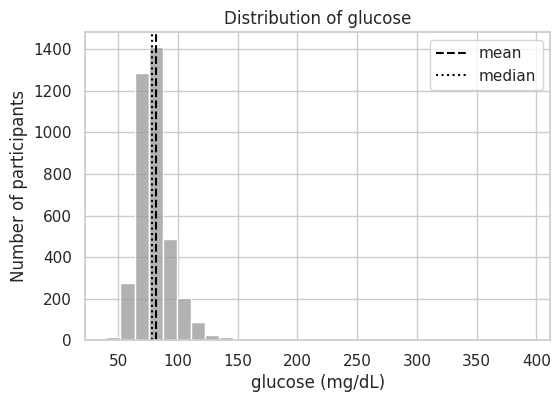

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(df["glucose"], bins=30, ax=ax, color="0.6")
ax.axvline(df["glucose"].mean(), color="black", linestyle="--", label="mean")
ax.axvline(df["glucose"].median(), color="black", linestyle=":", label="median")
ax.set_title("Distribution of glucose")
ax.set_xlabel("glucose (mg/dL)")
ax.set_ylabel("Number of participants")
ax.legend()
plt.show()

**🔎 What each line does**

- `fig, ax = plt.subplots(figsize=(6, 4))`  →  creates an empty chart (`fig`) with one drawing area (`ax`)
- `sns.histplot(df["glucose"], bins=30, ax=ax`  →  draws the histogram of glucose with 30 bars on that drawing area
- `ax.axvline(df["glucose"].mean()`  →  draws a vertical dashed line at the mean
- `ax.axvline(df["glucose"].median()`  →  draws a vertical dotted line at the median
- `ax.set_title`  →  sets the title
- `ax.set_xlabel`  →  labels the horizontal axis with the unit
- `ax.set_ylabel`  →  labels the vertical axis
- `ax.legend()`  →  shows what each line means
- `plt.show()`  →  displays the chart

**👀 What you should see:** a histogram with a long right tail; the dashed mean line sits to the right of the dotted median line.

**Reading it:** most people have glucose between about 70 and 90, but a few have very high values. Those few drag the mean (about 82) above the median (78): the distribution is *right-skewed*.

### ▶️ SEE · The same idea for age

Age is much more symmetric: its mean and median are close.

In [8]:
print(round(df["age"].mean(), 1), df["age"].median())

49.6 49.0


**👀 What you should see:** `49.6 49.0`.

### ▶️ SEE · A box plot

A box plot summarises one variable in a single picture. Dots are values beyond roughly 1.5 x IQR from the box.

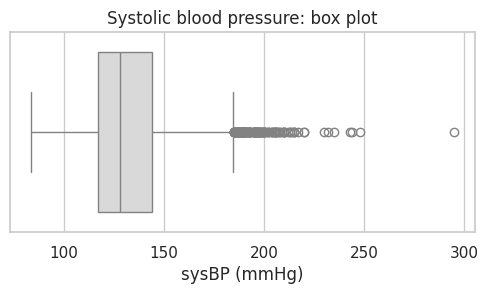

In [9]:
fig, ax = plt.subplots(figsize=(6, 2.6))
sns.boxplot(x=df["sysBP"], ax=ax, color="0.85")
ax.set_title("Systolic blood pressure: box plot")
ax.set_xlabel("sysBP (mmHg)")
plt.show()

**🔎 What each line does**

- `sns.boxplot(x=df["sysBP"]`  →  draws the box (middle half), the line (median), the whiskers and dots for unusual values
- `ax.set_title`  →  title
- `ax.set_xlabel`  →  label with the unit

**👀 What you should see:** a box centred near 128 with many dots on the right: high blood pressures are not rare.

### ▶️ SEE · Proportions of yes/no variables

For a 0/1 column the mean is the share of 1s. We multiply by 100 for percentages.

In [10]:
for col in ["male", "currentSmoker", "diabetes", "TenYearCHD"]:
    print(col, round(100 * df[col].mean(), 1), "%")

male 42.9 %
currentSmoker 49.4 %
diabetes 2.6 %
TenYearCHD 15.2 %


**👀 What you should see:** about 43.0 %, 49.4 %, 2.6 % and 15.2 %.

### ✏️ TRY · Exercise 2.1 · Median heart rate

Store the median of `heartRate` in `hr_median`. Then draw its histogram (30 bins) with a dashed vertical line at the median, a title and both axes labelled.

**Result variable(s):** `hr_median`

<details><summary>💡 Hint</summary>Copy the glucose example and change the column name.</details>

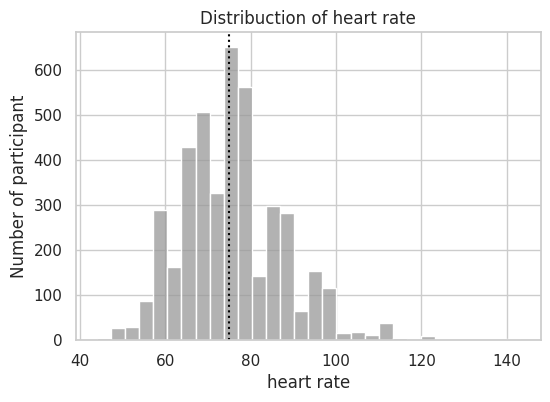

In [11]:
# [Exercise 2.1]
hr_median = df["heartRate"].median()   # step 1: df["heartRate"].median()
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(df["heartRate"], bins=30, ax=ax, color="0.6")      # step 2: sns.histplot(df["heartRate"], bins=30, ax=ax)
ax.axvline(df["heartRate"].median(), color="black", linestyle=":", label="median")         # step 3: ax.axvline(...)
ax.set_title("Distribuction of heart rate")
ax.set_xlabel("heart rate")
ax.set_ylabel("Number of participant")          # step 4: ax.set_title(...), ax.set_xlabel(...), ax.set_ylabel(...)
plt.show()

In [12]:
check("2.1")   # 🎯 run this cell to check your answer

✅ `hr_median`: correct!
✅ your chart has all the required parts.


### ✏️ TRY · Exercise 2.2 · Education levels

Store in `edu_props` the **proportion** of people at each education level (missing values excluded), sorted by level. Hint: `value_counts(normalize=True)` gives proportions and `sort_index()` sorts by level.

**Result variable(s):** `edu_props`

In [13]:
# [Exercise 2.2]
edu_props = df["education"].value_counts(normalize=True).sort_index()    # df["education"].value_counts(normalize=True).sort_index()
print(edu_props)

education
1.0    0.416
2.0    0.303
3.0    0.167
4.0    0.114
Name: proportion, dtype: float64


In [14]:
check("2.2")   # 🎯 run this cell to check your answer

✅ `edu_props`: correct!


### 🔍 ANALYZE · Question 2.1 · Mean versus median

For glucose the mean is about 82 and the median 78; for age they are 49.6 and 49. Complete: 'Glucose is skewed because ... whereas age is ...'. Name one thing a histogram cannot tell you.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [15]:
# [Question 2.1]
answer_2_1 = """Glucose is skewed because its mean of 82 is higher than its median of 78, which shows a few very high values are pulling the average up, whereas age is roughly symmetric because its mean of 49.6 is almost the same as its median of 49.

A histogram cannot tell you the relationship between two variables, for example it cannot show whether higher glucose is linked to higher CHD risk."""

In [16]:
check("Q2.1")   # 🎯 run this cell to check your answer

📝 answer saved (70 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 2.1

In a box plot, the dots beyond the whiskers are best described as:

- **A.** Errors that should be deleted
- **B.** Unusual values that deserve inspection
- **C.** The mean of each group
- **D.** Missing values

In [17]:
# [Knowledge check 2.1]
kc_2_1 = "B"   # type "A", "B", "C" or "D"

In [18]:
check("K2.1")   # 🎯 run this cell to check your answer

✅ `kc_2_1`: correct!


---
## Part 2 · Two variables together
*About 35 min · Research question(s): RQ3, RQ4, RQ5*

### 📘 LEARN · Match the chart to the variable types

| Variables | Useful chart |
|---|---|
| number vs number | scatter plot (use transparency when points overlap) |
| number vs category | box plot or violin plot for each group |
| category vs category | bars of proportions, or a cross-table |

A **violin plot** is a mirrored density curve: it shows the *shape* of each group. A pattern in any chart is **descriptive**; it does not prove a relationship in a wider population.

### ▶️ SEE · Number vs category: box plot by group

Blood pressure for people without (0) and with (1) recorded CHD.

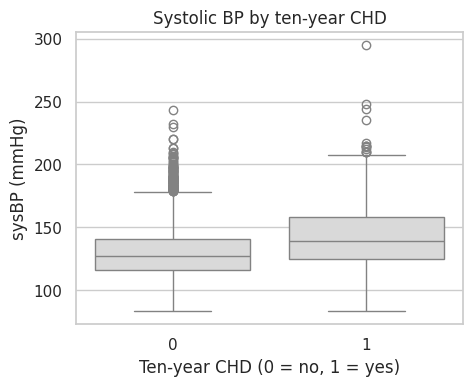

In [19]:
fig, ax = plt.subplots(figsize=(5, 3.8))
sns.boxplot(data=df, x="TenYearCHD", y="sysBP", color="0.85", ax=ax)
ax.set_title("Systolic BP by ten-year CHD")
ax.set_xlabel("Ten-year CHD (0 = no, 1 = yes)")
ax.set_ylabel("sysBP (mmHg)")
plt.show()

**🔎 What each line does**

- `sns.boxplot(data=df, x="TenYearCHD", y="sysBP"`  →  one box per CHD group: x is the category, y is the number
- `ax.set_title`  →  title
- `ax.set_xlabel`  →  x label
- `ax.set_ylabel`  →  y label with unit

**👀 What you should see:** the CHD box sits higher than the no-CHD box.

### ▶️ SEE · Number vs category: violin plot

Same data, drawn as violins; the `inner="quartile"` option marks the quartiles inside.

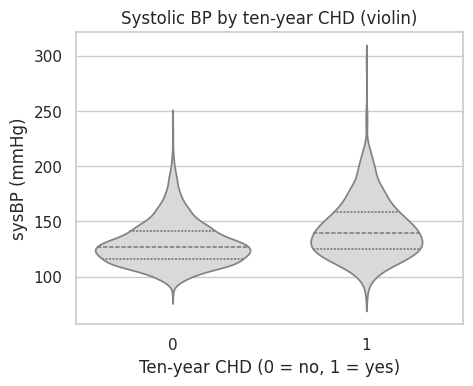

In [20]:
fig, ax = plt.subplots(figsize=(5, 3.8))
sns.violinplot(data=df, x="TenYearCHD", y="sysBP", color="0.85", inner="quartile", ax=ax)
ax.set_title("Systolic BP by ten-year CHD (violin)")
ax.set_xlabel("Ten-year CHD (0 = no, 1 = yes)")
ax.set_ylabel("sysBP (mmHg)")
plt.show()

**🔎 What each line does**

- `sns.violinplot(`  →  like the box plot but shows the whole shape; wide parts = many people
- `inner="quartile"`  →  draws the quartile lines inside each violin
- `ax.set_title`  →  title
- `ax.set_xlabel`  →  x label
- `ax.set_ylabel`  →  y label

**👀 What you should see:** two violins; the CHD one is shifted upward and has a longer upper tail.

### ▶️ SEE · Number vs number: scatter plot

Each dot is one person. `alpha=0.2` makes dots see-through so crowded areas look darker.

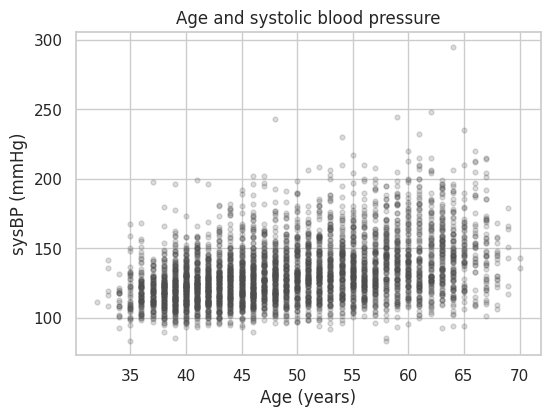

In [21]:
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(df["age"], df["sysBP"], alpha=0.2, s=12, color="0.3")
ax.set_title("Age and systolic blood pressure")
ax.set_xlabel("Age (years)")
ax.set_ylabel("sysBP (mmHg)")
plt.show()

**🔎 What each line does**

- `ax.scatter(df["age"], df["sysBP"]`  →  one dot per person: age on x, blood pressure on y
- `alpha=0.2`  →  20% opaque so overlapping dots show density
- `s=12`  →  dot size
- `ax.set_title`  →  title
- `ax.set_xlabel`  →  x label
- `ax.set_ylabel`  →  y label

**👀 What you should see:** a cloud that rises gently from left to right.

### ▶️ SEE · Smoking and other measurements (RQ3)

Mean of several columns for non-smokers (0) and smokers (1).

In [22]:
cols = ["age", "sysBP", "totChol", "BMI", "heartRate", "glucose"]
print(df.groupby("currentSmoker")[cols].mean().round(1))

                age  sysBP  totChol   BMI  heartRate  glucose
currentSmoker                                                
0              51.4  135.2    238.7  26.5       75.1     83.3
1              47.7  129.5    234.6  25.1       76.6     80.6


**👀 What you should see:** smokers are younger (about 48 vs 51 years) and have lower mean sysBP.

### ✏️ TRY · Exercise 2.3 · Blood pressure by sex

Store the median `sysBP` for each sex in `median_sbp_by_sex` (a Series indexed by 0 and 1). Then draw a violin plot of `sysBP` by `male` with a title and both axes labelled.

**Result variable(s):** `median_sbp_by_sex`

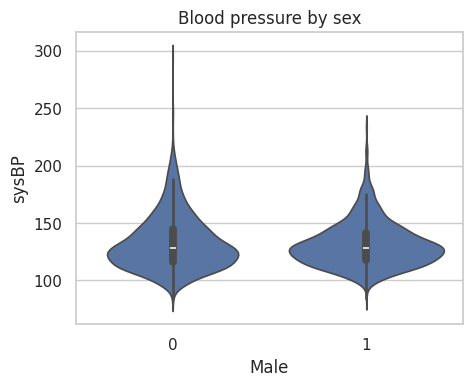

In [23]:
# [Exercise 2.3]
median_sbp_by_sex =df.groupby("male")["sysBP"].median()   # df.groupby("male")["sysBP"].median()
fig, ax = plt.subplots(figsize=(5, 3.8))
sns.violinplot(data=df, x="male", y="sysBP", ax=ax) # sns.violinplot(data=df, x="male", y="sysBP", ax=ax)
ax.set_title("Blood pressure by sex")
ax.set_xlabel("Male")
ax.set_ylabel("sysBP") # ax.set_title(...), ax.set_xlabel(...), ax.set_ylabel(...)
plt.show()

In [24]:
check("2.3")   # 🎯 run this cell to check your answer

✅ `median_sbp_by_sex`: correct!
✅ your chart has all the required parts.


### ✏️ TRY · Exercise 2.4 · BMI against blood pressure

Draw a scatter plot of `BMI` (x) against `sysBP` (y) with `alpha`, a title and both axes labelled. (Correlation comes in Part 3.)

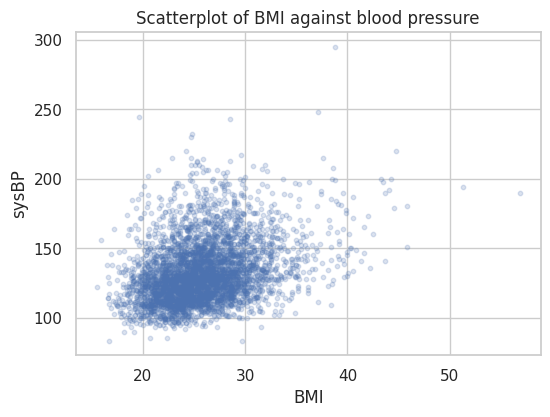

In [25]:
 # [Exercise 2.4]
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(df["BMI"], df["sysBP"], alpha=0.2, s=10 ) # step 1: ax.scatter(df["BMI"], df["sysBP"], alpha=0.2, s=12)
ax.set_title("Scatterplot of BMI against blood pressure")
ax.set_xlabel("BMI")
ax.set_ylabel("sysBP") # step 2: title and both axis labels
plt.show()

In [26]:
check("2.4")   # 🎯 run this cell to check your answer

✅ your chart has all the required parts.


### 💬 INTERPRET · Question 2.2 · Smokers have lower blood pressure?

In the smoking table, smokers have a *lower* mean sysBP than non-smokers. Does that mean smoking lowers blood pressure? Use another column of the same table to suggest a different explanation, and name the problem. Start: 'No, because ...'.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [27]:
# [Question 2.2]
answer_2_2 = """No, because from the the table, mean age of smokers is less than the non smokers, which tend to show that younger people tend to lower blood pressure, cholesterol, BMI and glucose. This does not mean smoking lower the blood pressure.

"""

In [28]:
check("Q2.2")   # 🎯 run this cell to check your answer

📝 answer saved (41 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 2.2

Which chart suits 'blood pressure (a number) for smokers vs non-smokers'?

- **A.** A box or violin plot per group
- **B.** A pie chart
- **C.** A scatter plot of two numbers
- **D.** No chart is possible

In [29]:
# [Knowledge check 2.2]
kc_2_2 = "A"   # type "A", "B", "C" or "D"

In [30]:
check("K2.2")   # 🎯 run this cell to check your answer

✅ `kc_2_2`: correct!


---
## Part 3 · Correlation
*About 30 min · Research question(s): RQ5, RQ7*

### 📘 LEARN · Pearson and Spearman

A **correlation** is one number between -1 and +1 that says how strongly two numeric variables move together.
- **Pearson r**: strength of a *straight-line* relationship. Sensitive to extreme values.
- **Spearman rho**: the same idea computed on *ranks* (1st, 2nd, 3rd...); it handles curves and extremes better.
- r close to 0 means no linear relationship; close to +1 or -1 means a strong one.
- **r squared** is the share of variation the two variables share: r = 0.4 means about 16%, not 40%.
- Correlation is **not causation**.

**📖 New words**

- **correlation**: a number from -1 to +1 for how strongly two variables move together
- **rank**: position in sorted order (1 = smallest)
- **pairwise**: each pair uses all rows where both values exist

### ▶️ SEE · A tiny example first

Five made-up people. Older age goes with higher blood pressure, so the correlation is positive.

In [31]:
ages = [30, 40, 50, 60, 70]
sbp = [110, 118, 125, 140, 152]
print(round(np.corrcoef(ages, sbp)[0, 1], 3))

0.989


**👀 What you should see:** a value near `0.99`: almost a perfect straight line.

### ▶️ SEE · One correlation in the real data

`.corr()` on a column compares it with another column.

In [32]:
print(round(df["age"].corr(df["sysBP"]), 3))

0.394


**👀 What you should see:** `0.393`.

### ▶️ SEE · Spearman instead of Pearson

Add `method="spearman"` to use ranks.

In [33]:
print(round(df["age"].corr(df["sysBP"], method="spearman"), 3))

0.391


**👀 What you should see:** about `0.39`, very similar, so the relationship is fairly straight.

### ▶️ SEE · The share of shared variation

Square r to get r squared.

In [34]:
r = df["age"].corr(df["sysBP"])
print(round(r ** 2, 3))

0.155


**👀 What you should see:** about `0.15`: age shares about 15% of the variation in sysBP.

### ▶️ SEE · A correlation matrix

One table of all pairs of the continuous variables.

In [35]:
cont = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
corr = df[cont].corr(method="spearman")
print(corr.round(2))

             age  cigsPerDay  totChol  sysBP  diaBP   BMI  heartRate  glucose
age         1.00       -0.21     0.29   0.39   0.21  0.15      -0.01     0.12
cigsPerDay -0.21        1.00    -0.04  -0.11  -0.09 -0.14       0.08    -0.09
totChol     0.29       -0.04     1.00   0.22   0.19  0.15       0.09     0.03
sysBP       0.39       -0.11     0.22   1.00   0.78  0.32       0.17     0.12
diaBP       0.21       -0.09     0.19   0.78   1.00  0.37       0.18     0.05
BMI         0.15       -0.14     0.15   0.32   0.37  1.00       0.06     0.07
heartRate  -0.01        0.08     0.09   0.17   0.18  0.06       1.00     0.10
glucose     0.12       -0.09     0.03   0.12   0.05  0.07       0.10     1.00


**👀 What you should see:** a symmetric 8 x 8 table with 1.00 on the diagonal.

### ▶️ SEE · A heat map of the matrix

A heat map turns the table into colours, with the numbers printed in each cell so it does not rely on colour alone. We hide the duplicate upper half.

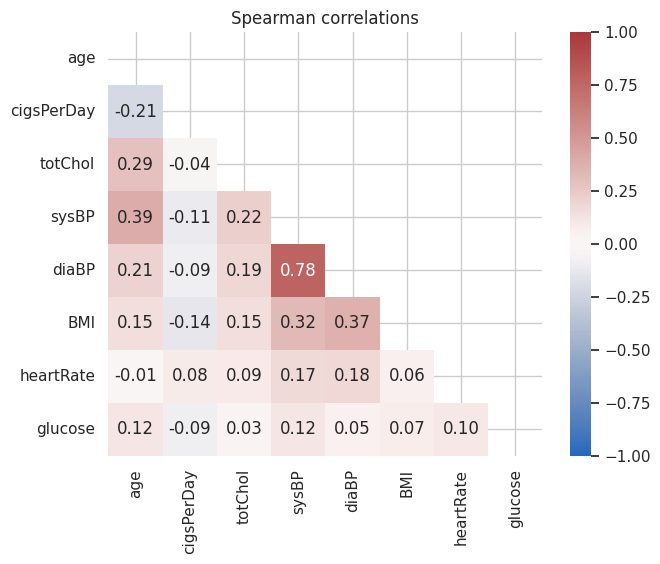

In [36]:
mask = np.triu(np.ones_like(corr, dtype=bool))
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, center=0, ax=ax)
ax.set_title("Spearman correlations")
plt.show()

**🔎 What each line does**

- `np.triu(np.ones_like(corr, dtype=bool))`  →  builds a True/False grid marking the upper triangle, which would only repeat the lower one
- `sns.heatmap(corr, mask=mask`  →  draws the table as coloured squares, hiding the masked half
- `annot=True, fmt=".2f"`  →  prints each number with 2 decimals
- `vmin=-1, vmax=1, center=0`  →  colour scale from -1 to +1 with 0 in the middle
- `ax.set_title`  →  title

**👀 What you should see:** the strongest square is sysBP with diaBP (about 0.78).

### ✏️ TRY · Exercise 2.5 · Two correlations

Store the Pearson correlation of `age` with `diaBP` in `r_age_dia` and the Spearman correlation of `age` with `sysBP` in `rho_age_sysbp` (use `.corr(...)`).

**Result variable(s):** `r_age_dia`, `rho_age_sysbp`

In [37]:
# [Exercise 2.5]
r_age_dia = df["age"].corr(df["diaBP"])       # df["age"].corr(df["diaBP"])
rho_age_sysbp = df["age"].corr(df["sysBP"], method="spearman")    # df["age"].corr(df["sysBP"], method="spearman")
print(r_age_dia, rho_age_sysbp)

0.20558552098290586 0.39097795301897326


In [38]:
check("2.5")   # 🎯 run this cell to check your answer

✅ `r_age_dia`: correct!
✅ `rho_age_sysbp`: correct!


### ✏️ TRY · Exercise 2.6 · The strongest pair

From the matrix `corr` above, `corr['sysBP']` shows sysBP's correlation with each variable. Store in `strongest_with_sysbp` the name of the variable (not sysBP itself) with the largest **absolute** correlation with sysBP. Hint: drop `'sysBP'`, take `.abs()`, then `.idxmax()`.

**Result variable(s):** `strongest_with_sysbp`

In [39]:
# [Exercise 2.6]
others = corr["sysBP"].drop("sysBP")     # step 1: remove sysBP itself
strongest_with_sysbp =others.abs().idxmax()           # step 2: others.abs().idxmax()
print(strongest_with_sysbp)

diaBP


In [40]:
check("2.6")   # 🎯 run this cell to check your answer

✅ `strongest_with_sysbp`: correct!


### 🔍 ANALYZE · Question 2.3 · Why is diaBP a poor predictor of sysBP?

sysBP and diaBP are strongly correlated. Why would using diaBP to predict sysBP give a misleadingly good model? Name what we do about it later in this course.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [41]:
# [Question 2.3]
answer_2_3 = """Using diaBP to predict sysBP gives a misleadingly good model because the two variables measure almost the same thing, both are blood pressure taken at the same time, so one almost perfectly predicts the other.
This is not useful prediction, it is just leakage from a twin variable, and it hides whether other factors like age or smoking really matter. We can check for multicollinearity and dropping one of a pair of highly correlated predictors, so we keep only one of sysBP and diaBP in the model.

"""

In [42]:
check("Q2.3")   # 🎯 run this cell to check your answer

📝 answer saved (87 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 2.3

Age and sysBP have r of about 0.39. Which statement is correct?

- **A.** Age explains 39% of the variation in sysBP
- **B.** Ageing causes a 39% rise in sysBP
- **C.** About 15% of the variation is shared (r squared); this says nothing about cause
- **D.** The relationship is not real

In [43]:
# [Knowledge check 2.3]
kc_2_3 = "C"   # type "A", "B", "C" or "D"

In [44]:
check("K2.3")   # 🎯 run this cell to check your answer

✅ `kc_2_3`: correct!


---
## Part 4 · Comparing two groups
*About 40 min · Research question(s): RQ6, RQ9*

### 📘 LEARN · Is a difference real, or just chance?

Two groups will almost never have exactly the same average. A **hypothesis test** asks whether the difference is bigger than chance alone would easily produce.
1. Start with the **null hypothesis**: *there is no real difference*.
2. The **p-value** is the probability of seeing a difference *at least this large if the null hypothesis were true*. Small p (below 0.05 by convention) means 'surprising if nothing is going on'.
3. The p-value is **not** the probability that the null is true, and it says **nothing about how big or important** the difference is.

**📖 New words**

- **null hypothesis**: the assumption that there is no real difference
- **p-value**: how surprising the data would be if the null hypothesis were true
- **confidence interval**: a range of plausible values for the true difference
- **effect size**: how big a difference is, not just whether it is detectable

### ▶️ SEE · Step 1: split the two groups

We take the blood pressures of men and of women into two separate lists of numbers.

In [45]:
male_bp = df.loc[df["male"] == 1, "sysBP"]
female_bp = df.loc[df["male"] == 0, "sysBP"]
print(len(male_bp), len(female_bp))

1820 2420


**👀 What you should see:** `1820 2420`.

### ▶️ SEE · Step 2: the difference in means

This is the **effect** in real units (mmHg): men minus women.

In [46]:
diff = male_bp.mean() - female_bp.mean()
print(round(diff, 2), "mmHg")

-1.6 mmHg


**👀 What you should see:** about `-1.6 mmHg`.

**📖 New words**

- **Welch t-test**: compares two group means without assuming equal spread

### ▶️ SEE · Step 3: the Welch t-test

`stats.ttest_ind(..., equal_var=False)` is the Welch t-test: it compares two means without assuming the groups have equal spread. It returns a t statistic and a p-value.

In [47]:
welch = stats.ttest_ind(male_bp, female_bp, equal_var=False)
print(round(welch.pvalue, 4))

0.0162


**👀 What you should see:** a p-value of about `0.016`.

### ▶️ SEE · Step 4: the Mann-Whitney U test

A rank-based alternative that does not rely on means. It has the same style: two groups in, a p-value out.

In [48]:
mwu = stats.mannwhitneyu(male_bp, female_bp)
print(round(mwu.pvalue, 4))

0.7198


**👀 What you should see:** a p-value of about `0.72`: unlike the Welch test, this rank-based test does not detect a difference.

The Welch test says the sex difference is *statistically detectable* (p below 0.05), although the rank-based Mann-Whitney test does not (p about 0.72): the two tests ask slightly different questions. Either way the difference is only about 1.6 mmHg. **Is that important?** To answer, we need an effect size.

### 📘 LEARN · Effect sizes: how big is the difference?

- **Mean difference with a 95% confidence interval** is in real units (mmHg), so it is easy to interpret.
- **Cohen's d** is the difference divided by the *typical spread* (the pooled standard deviation). It lets you compare different variables. Rough guide: |d| of 0.2 small, 0.5 medium, 0.8 large.
- With thousands of people, even a trivial difference can give p < 0.05.

### ▶️ SEE · Cohen's d, built from small pieces

We write one reusable function. A **function** (Notebook 1, Part 8) packs steps under one name.

In [49]:
def cohens_d(a, b):
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    pooled_var = ((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2)
    return (a.mean() - b.mean()) / np.sqrt(pooled_var)

print(round(cohens_d(male_bp, female_bp), 3))

-0.073


**🔎 What each line does**

- `def cohens_d(a, b):`  →  defines a function that takes two groups, a and b
- `pd.Series(a).dropna()`  →  turns each group into a pandas column and removes missing values
- `pooled_var = `  →  the average spread of the two groups (variance = standard deviation squared), weighted by group size
- `return (a.mean() - b.mean()) / np.sqrt(pooled_var)`  →  mean difference divided by the pooled standard deviation (square root of the variance)
- `print(round(cohens_d(male_bp, female_bp), 3))`  →  uses the function on men and women

**👀 What you should see:** about `-0.07`: a very small effect.

### ▶️ SEE · A confidence interval for the difference

Another reusable function; it returns the difference and the lower and upper ends of the 95% interval.

In [50]:
def welch_ci(a, b, level=0.95):
    a, b = pd.Series(a).dropna(), pd.Series(b).dropna()
    va, vb = a.var() / len(a), b.var() / len(b)
    dof = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    diff = a.mean() - b.mean()
    margin = stats.t.ppf(0.5 + level / 2, dof) * np.sqrt(va + vb)
    return diff, diff - margin, diff + margin

**🔎 What each line does**

- `a, b = pd.Series(a).dropna()`  →  tidy both groups (as before)
- `va, vb = `  →  the squared standard error of each group mean: how uncertain each mean is
- `dof = `  →  the 'degrees of freedom' used by the Welch test (a formula you can take as given)
- `diff = a.mean() - b.mean()`  →  the difference in means
- `margin = stats.t.ppf(`  →  the half-width of the interval: a critical value times the standard error of the difference
- `return diff, diff - margin, diff + margin`  →  gives back the difference, its lower limit and its upper limit

**👀 What you should see:** nothing is printed: the function is only defined here.

### ▶️ SEE · Use it on men and women

Unpack the three returned numbers into three names.

In [51]:
diff, lo, hi = welch_ci(male_bp, female_bp)
print(f"{diff:.2f} mmHg, 95% CI {lo:.2f} to {hi:.2f}")

-1.60 mmHg, 95% CI -2.90 to -0.29


**👀 What you should see:** about `-1.60 mmHg, 95% CI -2.90 to -0.29`: even the top of the interval is a tiny difference.

⚠️ **Statistically detectable is not the same as important.** With 4,240 people, a 1.6 mmHg difference (d about -0.07) reaches p below 0.05, but it is far too small to matter in practice.

### ✏️ TRY · Exercise 2.7 · Smokers versus non-smokers: the Welch test

Compare `sysBP` of current smokers (`smokers`) and non-smokers (`non_smokers`). Store the Welch t-test p-value in `welch_p` and Cohen's d (smokers minus non-smokers) in `d_smoking`.

**Result variable(s):** `welch_p`, `d_smoking`

In [52]:
# [Exercise 2.7]
smokers = df.loc[df["currentSmoker"] == 1, "sysBP"]
non_smokers = df.loc[df["currentSmoker"] == 0, "sysBP"]
welch_p = stats.ttest_ind(smokers, non_smokers, equal_var=False).pvalue     # stats.ttest_ind(smokers, non_smokers, equal_var=False).pvalue
d_smoking = cohens_d(smokers, non_smokers)   # cohens_d(smokers, non_smokers)
print(welch_p, d_smoking)

1.4792582646253092e-17 -0.26275911160261206


In [53]:
check("2.7")   # 🎯 run this cell to check your answer

✅ `welch_p`: correct!
✅ `d_smoking`: correct!


### ✏️ TRY · Exercise 2.8 · Smokers versus non-smokers: the interval

Use `welch_ci` on the same two groups. Store the three returned values in `smoking_diff`, `ci_low` and `ci_high`.

**Result variable(s):** `smoking_diff`, `ci_low`, `ci_high`

In [54]:
# [Exercise 2.8]
smokers = df.loc[df["currentSmoker"] == 1, "sysBP"]
non_smokers = df.loc[df["currentSmoker"] == 0, "sysBP"]
smoking_diff, ci_low, ci_high = welch_ci(smokers, non_smokers)    # welch_ci(smokers, non_smokers)
print(smoking_diff, ci_low, ci_high)

-5.740784195915467 -7.05464388276228 -4.4269245090686535


In [55]:
check("2.8")   # 🎯 run this cell to check your answer

✅ `smoking_diff`: correct!
✅ `ci_low`: correct!
✅ `ci_high`: correct!


### ✏️ TRY · Exercise 2.9 · Mann-Whitney for smokers

Run the Mann-Whitney test on the same groups. Store the p-value in `mwu_p`. Then compute the **common-language effect size** `cles` = U / (n1 x n2), where U is `.statistic` for the smokers and n1, n2 are the group sizes. It is the chance that a random smoker has a *higher* sysBP than a random non-smoker.

**Result variable(s):** `mwu_p`, `cles`

In [56]:
# [Exercise 2.9]
smokers = df.loc[df["currentSmoker"] == 1, "sysBP"]
non_smokers = df.loc[df["currentSmoker"] == 0, "sysBP"]
result = stats.mannwhitneyu(smokers, non_smokers)     # step 1: stats.mannwhitneyu(smokers, non_smokers)
mwu_p = result.pvalue      # step 2: result.pvalue
cles = result.statistic / (len(smokers) * len(non_smokers))       # step 3: result.statistic / (len(smokers) * len(non_smokers))
print(mwu_p, cles)

1.784901371803224e-17 0.4245639801725721


In [57]:
check("2.9")   # 🎯 run this cell to check your answer

✅ `mwu_p`: correct!
✅ `cles`: correct!


### 💬 INTERPRET · Question 2.4 · Detectable but is it important?

For men vs women the p-value is about 0.016 and Cohen's d about -0.07. Complete: 'The difference is statistically ... but ... because ...'.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [58]:
# [Question 2.4]
answer_2_4 = """The difference is statistically significant because the p-value of 0.016 is below 0.05, but it is not practically important because Cohen's d of -0.07 is very small.

"""

In [59]:
check("Q2.4")   # 🎯 run this cell to check your answer

📝 answer saved (27 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 2.4

A p-value of 0.01 means:

- **A.** There is a 1% chance the null hypothesis is true
- **B.** The effect is large
- **C.** If the null hypothesis were true, a result at least this extreme would occur about 1% of the time
- **D.** The result will replicate 99% of the time

In [60]:
# [Knowledge check 2.4]
kc_2_4 = "C"   # type "A", "B", "C" or "D"

In [61]:
check("K2.4")   # 🎯 run this cell to check your answer

✅ `kc_2_4`: correct!


---
## Part 5 · Two yes/no variables
*About 35 min · Research question(s): RQ8, RQ9*

### 📘 LEARN · Cross-tables, chi-square and odds ratios

For two yes/no variables, count people in each combination (a **cross-table**). The **chi-square test** compares these counts with the counts expected if the variables were unrelated.
- It works well when every *expected* count is about 5 or more.
- **Cramer's V** (0 to 1) measures the strength of the association.
- The **odds** of an outcome are (people with it) / (people without). The **odds ratio (OR)** compares the odds in two groups; **OR = 1 means no association**. If the 95% interval includes 1, the data are compatible with no association.
- Odds are not risks: when an outcome is common (here 15%) an OR looks bigger than the real risk ratio.

**📖 New words**

- **cross-table**: counts for every combination of two categories
- **odds**: people with the outcome divided by people without
- **odds ratio**: odds in one group divided by odds in another
- **expected count**: the count we would see if the two variables were unrelated

### ▶️ SEE · A cross-table of smoking and CHD

Rows: smoking (0/1). Columns: CHD (0/1).

In [62]:
table = pd.crosstab(df["currentSmoker"], df["TenYearCHD"])
print(table)

TenYearCHD        0    1
currentSmoker           
0              1834  311
1              1762  333


**👀 What you should see:** four counts; most people are in the CHD = 0 column.

### ▶️ SEE · Proportions inside each row

`normalize="index"` turns each row into proportions that add to 1.

In [63]:
print(pd.crosstab(df["currentSmoker"], df["TenYearCHD"], normalize="index").round(3))

TenYearCHD         0      1
currentSmoker              
0              0.855  0.145
1              0.841  0.159


**👀 What you should see:** about 14.5% CHD among non-smokers and 15.9% among smokers.

### ▶️ SEE · The chi-square test

`chi2_contingency` returns four things: the statistic, the p-value, the degrees of freedom and the expected counts.

In [64]:
chi2, p, dof, expected = stats.chi2_contingency(table, correction=False)
print(round(chi2, 2), round(p, 3))

1.6 0.205


**👀 What you should see:** a p-value of about `0.15`: not statistically detectable.

### ▶️ SEE · Check the expected counts

The smallest expected count should be about 5 or more.

In [65]:
print(expected.min().round(1))

318.2


**👀 What you should see:** about `318.2`, far above 5, so the test is trustworthy.

### ▶️ SEE · The odds ratio, step by step

Name the four cells, then work out the odds in each row and divide them.

In [66]:
a, b_ = table.loc[1, 1], table.loc[1, 0]
c, d = table.loc[0, 1], table.loc[0, 0]
odds_ratio = (a * d) / (b_ * c)
print(round(odds_ratio, 2))

1.11


**🔎 What each line does**

- `a, b_ = table.loc[1, 1], table.loc[1, 0]`  →  smokers (row 1): `a` = with CHD, `b_` = without CHD
- `c, d = table.loc[0, 1], table.loc[0, 0]`  →  non-smokers (row 0): `c` = with CHD, `d` = without CHD
- `odds_ratio = (a * d) / (b_ * c)`  →  (odds in smokers) / (odds in non-smokers), simplified: (a/b)/(c/d) = a*d/(b*c)

**👀 What you should see:** about `1.11`: smokers have about 11% higher odds of CHD in this file.

### ▶️ SEE · A confidence interval for the odds ratio

We work on the log scale, where the interval is symmetric, then convert back with `np.exp`.

In [67]:
se_log = np.sqrt(1 / a + 1 / b_ + 1 / c + 1 / d)
low = np.exp(np.log(odds_ratio) - 1.96 * se_log)
high = np.exp(np.log(odds_ratio) + 1.96 * se_log)
print(round(low, 2), round(high, 2))

0.94 1.32


**🔎 What each line does**

- `se_log = `  →  the standard error of the log odds ratio, from the four counts
- `low = np.exp(`  →  log(OR) minus 1.96 standard errors, converted back to an odds ratio
- `high = np.exp(`  →  log(OR) plus 1.96 standard errors, converted back

**👀 What you should see:** about `0.94 1.32`. The interval includes 1, so the data are compatible with no association.

### ▶️ SEE · Two reusable helpers

Now we pack Cramer's V and the odds ratio into functions, so we can use them on other variable pairs. Nothing new, just the same steps.

In [68]:
def cramers_v(table):
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))

def odds_ratio_ci(table):
    a, b_ = table.loc[1, 1], table.loc[1, 0]
    c, d = table.loc[0, 1], table.loc[0, 0]
    odds_ratio = (a * d) / (b_ * c)
    se_log = np.sqrt(1 / a + 1 / b_ + 1 / c + 1 / d)
    low, high = np.exp(np.log(odds_ratio) + np.array([-1.96, 1.96]) * se_log)
    return odds_ratio, low, high

**🔎 What each line does**

- `def cramers_v(table):`  →  a function that takes a cross-table
- `chi2 = stats.chi2_contingency`  →  the chi-square statistic
- `return np.sqrt(`  →  converts the statistic to a 0-1 strength (Cramer's V)
- `def odds_ratio_ci(table):`  →  a function that repeats the odds-ratio steps above
- `return odds_ratio, low, high`  →  returns the odds ratio and its 95% interval

**👀 What you should see:** nothing printed; both functions are now defined.

### ▶️ SEE · Use them for smoking and CHD

In [69]:
print(round(cramers_v(table), 3))
print([round(float(x), 2) for x in odds_ratio_ci(table)])

0.019
[1.11, 0.94, 1.32]


**👀 What you should see:** `0.019` and `[1.11, 0.94, 1.32]`: a very weak association.

### ✏️ TRY · Exercise 2.10 · Sex and CHD

Build the cross-table `table_sex` of `male` and `TenYearCHD`. Store the chi-square p-value in `chi2_sex_p` (`correction=False`, the second returned value), Cramer's V in `v_sex` and the odds ratio (first value of `odds_ratio_ci`) in `or_sex`.

**Result variable(s):** `chi2_sex_p`, `v_sex`, `or_sex`

In [70]:
# [Exercise 2.10]
table_sex = pd.crosstab(df["male"], df["TenYearCHD"])
chi2_sex_p = stats.chi2_contingency(table_sex, correction=False)[1]   # stats.chi2_contingency(table_sex, correction=False)[1]
v_sex = cramers_v(table_sex)       # cramers_v(table_sex)
or_sex =odds_ratio_ci(table_sex)[0]      # odds_ratio_ci(table_sex)[0]
print(chi2_sex_p, v_sex, or_sex)

8.691397433315018e-09 0.08837357241125839 1.63485065579191


In [71]:
check("2.10")   # 🎯 run this cell to check your answer

✅ `chi2_sex_p`: correct!
✅ `v_sex`: correct!
✅ `or_sex`: correct!


### ✏️ TRY · Exercise 2.11 · Diabetes and CHD: check the condition

For `diabetes` and `TenYearCHD`, store the smallest expected count in `min_expected_count` (the 4th value from `chi2_contingency`, then `.min()`) and the odds ratio in `or_diabetes`.

**Result variable(s):** `min_expected_count`, `or_diabetes`

In [72]:
# [Exercise 2.11]
table_diab = pd.crosstab(df["diabetes"], df["TenYearCHD"])
min_expected_count = stats.chi2_contingency(table_diab, correction=False)[3].min()   # stats.chi2_contingency(table_diab, correction=False)[3].min()
or_diabetes = odds_ratio_ci(table_diab)[0]          # odds_ratio_ci(table_diab)[0]
print(min_expected_count, or_diabetes)

16.55566037735849 3.3851617237738747


In [73]:
check("2.11")   # 🎯 run this cell to check your answer

✅ `min_expected_count`: correct!
✅ `or_diabetes`: correct!


### 💬 INTERPRET · Question 2.5 · No detectable smoking-CHD link: is smoking harmless?

Here the smoking-CHD test is not statistically detectable (OR about 1.11, 95% CI 0.94 to 1.32). Does that mean smoking does not affect CHD? Give two reasons. Start: 'No, because ...'.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [74]:
# [Question 2.5]
answer_2_5 = """No, because a non-significant result does not prove there is no effect, it only means we could not detect it clearly in this sample.
First, the confidence interval from 0.94 to 1.32 includes 1.0, but it also includes up to a 32% higher odds of CHD, so there could still real effect.
Second, smokers in this data are younger on average, and younger age lowers CHD risk, so age may be hiding the true harmful effect of smoking unless we adjust for it.

"""

In [75]:
check("Q2.5")   # 🎯 run this cell to check your answer

📝 answer saved (83 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 2.5

Which condition makes a chi-square test unreliable?

- **A.** Several expected counts below about 5
- **B.** A p-value below 0.05
- **C.** More than 1,000 observations
- **D.** A binary outcome

In [76]:
# [Knowledge check 2.5]
kc_2_5 = "A"   # type "A", "B", "C" or "D"

In [77]:
check("K2.5")   # 🎯 run this cell to check your answer

✅ `kc_2_5`: correct!


---
## Part 6 · More than two groups
*About 30 min · Research question(s): RQ6, RQ9*

### 📘 LEARN · ANOVA and Kruskal-Wallis

To compare **three or more** groups at once:
- **One-way ANOVA** tests whether *any* group mean differs. **Kruskal-Wallis** is the rank-based version.
- A significant overall test only says that *some* difference exists; it does not say which groups differ.
- **Eta squared** is the share of total variation explained by group membership (0 to 1).

**📖 New words**

- **ANOVA**: analysis of variance: do several group means differ?
- **eta squared**: share of variation explained by the groups

### ▶️ SEE · Step 1: one list per group

Education has four levels. We drop people with unknown education and make one list of sysBP values per level.

In [78]:
known_edu = df.dropna(subset=["education"])
edu_groups = [g["sysBP"].to_numpy() for _, g in known_edu.groupby("education")]
print(len(edu_groups), [len(g) for g in edu_groups])

4 [1720, 1253, 689, 473]


**👀 What you should see:** four groups of sizes 1720, 1253, 689 and 473.

### ▶️ SEE · Step 2: ANOVA and Kruskal-Wallis

The `*` unpacks the list so each group is passed as a separate argument.

In [79]:
print(f"ANOVA p = {stats.f_oneway(*edu_groups).pvalue:.1e}")
print(f"Kruskal-Wallis p = {stats.kruskal(*edu_groups).pvalue:.1e}")

ANOVA p = 3.8e-17
Kruskal-Wallis p = 9.1e-17


**👀 What you should see:** both p-values are very small.

### ▶️ SEE · Step 3: how much variation do the groups explain?

Eta squared = (variation between group means) / (total variation).

In [80]:
def eta_squared(groups):
    allv = np.concatenate(groups)
    ss_between = sum(len(g) * (g.mean() - allv.mean()) ** 2 for g in groups)
    return ss_between / ((allv - allv.mean()) ** 2).sum()

print(round(eta_squared(edu_groups), 3))

0.019


**🔎 What each line does**

- `allv = np.concatenate(groups)`  →  puts all the values from all groups into one long list
- `ss_between = sum(`  →  for each group: size x (group mean - overall mean) squared; added up; this is the variation *between* groups
- `return ss_between / `  →  divides by the total variation of all values around the overall mean
- `print(round(eta_squared(edu_groups), 3))`  →  uses the function on the education groups

**👀 What you should see:** about `0.02`: education explains only about 2% of the variation in sysBP.

### ▶️ SEE · Education groups also differ in age

A reason for caution: the lowest education level has the oldest people.

In [81]:
print(known_edu.groupby("education")[["sysBP", "age"]].mean().round(1))

           sysBP   age
education             
1.0        135.8  51.9
2.0        130.8  47.3
3.0        129.4  48.7
4.0        128.1  48.2


**👀 What you should see:** level 1 has the highest sysBP and the highest mean age.

### ✏️ TRY · Exercise 2.12 · Age bands and blood pressure

Cut `age` into the bands `age_band` with `pd.cut`. Build `age_groups` (one array of `sysBP` per band) and compute `eta_sq_age_band` with `eta_squared` and `kruskal_p_age_band`.

**Result variable(s):** `eta_sq_age_band`, `kruskal_p_age_band`

In [82]:
# [Exercise 2.12]
age_band = pd.cut(df["age"], bins=[30, 40, 50, 60, 70])
age_groups = [g["sysBP"].to_numpy() for _, g in df.groupby(age_band, observed=True)]                   # [g["sysBP"].to_numpy() for _, g in df.groupby(age_band, observed=True)]
eta_sq_age_band = eta_squared(age_groups)             # eta_squared(age_groups)
kruskal_p_age_band = stats.kruskal(*age_groups).pvalue         # stats.kruskal(*age_groups).pvalue
print(eta_sq_age_band, kruskal_p_age_band)

0.14094370668812117 5.830875071547239e-126


In [83]:
check("2.12")   # 🎯 run this cell to check your answer

✅ `eta_sq_age_band`: correct!
✅ `kruskal_p_age_band`: correct!


### 🔍 ANALYZE · Question 2.6 · Education and blood pressure

Eta squared is about 0.02 for education but about 0.14 for age bands. Which matters more for sysBP? Level 1 education also has the oldest people. What does that suggest? Start: 'Age matters more because ...'.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [84]:
# [Question 2.6]
answer_2_6 = """Age matters more because its eta squared of 0.14 means age bands explain about 14% of the variation in sysBP, while education only explains about 2%.

Level 1 education also has the oldest people, which suggests that the higher blood pressure seen in that group may not be caused by education itself, but by age.

"""

In [85]:
check("Q2.6")   # 🎯 run this cell to check your answer

📝 answer saved (55 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 2.6

After a significant ANOVA you run six pairwise tests. What should you do?

- **A.** Nothing
- **B.** Adjust the p-values for the number of comparisons (for example Holm)
- **C.** Only report the smallest p
- **D.** Delete groups that differ

In [86]:
# [Knowledge check 2.6]
kc_2_6 = "B"   # type "A", "B", "C" or "D"

In [87]:
check("K2.6")   # 🎯 run this cell to check your answer

✅ `kc_2_6`: correct!


---
## Part 7 · How uncertain is a correlation?
*About 20 min · Research question(s): RQ7, RQ9*

### 📘 LEARN · A confidence interval for r

A correlation from a sample is only an estimate. The **Fisher z method** gives a 95% interval in three small steps:
1. `z = np.arctanh(r)` (stretches r so the maths works),
2. `se = 1 / np.sqrt(n - 3)` (the standard error; n = number of people),
3. interval = `np.tanh(z - 1.96 * se)` to `np.tanh(z + 1.96 * se)` (converts back).

### ▶️ SEE · Step 1: r and n

In [88]:
r = df["age"].corr(df["sysBP"])
n = len(df)
print(round(r, 3), n)

0.394 4240


**👀 What you should see:** `0.394 4240`.

### ▶️ SEE · Step 2: z and its standard error

In [89]:
z = np.arctanh(r)
se = 1 / np.sqrt(n - 3)
print(round(z, 3), round(se, 4))

0.417 0.0154


**👀 What you should see:** about `0.417 0.0154`.

### ▶️ SEE · Step 3: the interval

In [90]:
low = np.tanh(z - 1.96 * se)
high = np.tanh(z + 1.96 * se)
print(round(low, 3), round(high, 3))

0.368 0.419


**👀 What you should see:** about `0.368 0.419`: narrow, because n is large.

### ▶️ SEE · A slope is easier to read than r

`linregress(...).slope` is the average change in sysBP for one more year of age (an association, not an effect).

In [91]:
slope = stats.linregress(df["age"], df["sysBP"]).slope
print(round(slope, 2), "mmHg per year;", round(10 * slope, 1), "per decade")

1.01 mmHg per year; 10.1 per decade


**👀 What you should see:** about `1.01 mmHg per year; 10.1 per decade`.

### ✏️ TRY · Exercise 2.13 · Age and diastolic pressure

Repeat the three steps for `age` and `diaBP`. Store `r_age_dia`, the interval ends `r_ci_low` and `r_ci_high`, and the slope per decade in `slope_dia_per_decade` (slope x 10).

**Result variable(s):** `r_age_dia`, `r_ci_low`, `r_ci_high`, `slope_dia_per_decade`

In [92]:
# [Exercise 2.13]
n = len(df)
r_age_dia = df["age"].corr(df["diaBP"])                       # df["age"].corr(df["diaBP"])
r_ci_low, r_ci_high = np.tanh(np.arctanh(r_age_dia) - 1.96 / np.sqrt(n - 3)), np.tanh(np.arctanh(r_age_dia) + 1.96 / np.sqrt(n - 3))       # np.tanh(np.arctanh(r) -/+ 1.96 / np.sqrt(n - 3))
slope_dia_per_decade = 10 * stats.linregress(df["age"], df["diaBP"]).slope            # 10 * stats.linregress(df["age"], df["diaBP"]).slope
print(r_age_dia, r_ci_low, r_ci_high, slope_dia_per_decade)

0.20558552098290586 0.1765762519641932 0.23423794834110487 2.8562010624166905


In [93]:
check("2.13")   # 🎯 run this cell to check your answer

✅ `r_age_dia`: correct!
✅ `r_ci_low`: correct!
✅ `r_ci_high`: correct!
✅ `slope_dia_per_decade`: correct!


### 💬 INTERPRET · Question 2.7 · Is age associated with systolic BP?

Summarise age and sysBP in 2-3 sentences using r, its interval and the slope per decade. What stops you saying ageing *raises* blood pressure here?

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [94]:
# [Question 2.7]
answer_2_7 = """Age and sysBP are weakly positively correlated, r = 0.21, 95% CI 0.18 to 0.23, with sysBP increasing by about 2.86 mmHg per decade of age.
This means older people in this sample tend to have slightly higher diastolic blood pressure, but the correlation is weak so age explains only about 4% of the variation in diaBP.
We cannot say ageing raises blood pressure here because this is observational, cross-sectional data, so confounding factors like BMI, smoking, and cholesterol, and the fact that we did not follow the same people over time, could explain the association.
"""

In [95]:
check("Q2.7")   # 🎯 run this cell to check your answer

📝 answer saved (96 words). Your teacher will read it.


---
## Part 8 · Many tests, many chances to be fooled
*About 35 min · Research question(s): RQ4, RQ9*

### 📘 LEARN · Multiple testing

Test 20 truly unrelated variables at alpha = 0.05 and you expect **one false positive** by chance alone. Two common corrections:
- **Bonferroni**: multiply every p-value by the number of tests. Strict.
- **Benjamini-Hochberg (BH)**: controls the *false discovery rate* (the share of 'discoveries' that are false). Less strict.

**📖 New words**

- **false positive**: a 'significant' result when nothing real is going on
- **Bonferroni**: multiply p-values by the number of tests
- **false discovery rate**: the expected share of discoveries that are false

### ▶️ SEE · A tiny example of correction

Four made-up p-values. Bonferroni multiplies each by 4 (and caps at 1).

In [96]:
from statsmodels.stats.multitest import multipletests
p_values = [0.001, 0.02, 0.03, 0.40]
print(multipletests(p_values, method="bonferroni")[1])

[0.004 0.08  0.12  1.   ]


**👀 What you should see:** `[0.004 0.08 0.12 1.]`: only the first stays below 0.05.

### ▶️ SEE · Step 1: one comparison by CHD status

Is mean age different for people with and without CHD? (`cont` is the list of eight continuous variables from Part 3.)

In [97]:
with_chd = df.loc[df["TenYearCHD"] == 1, "age"]
without = df.loc[df["TenYearCHD"] == 0, "age"]
print(round(stats.ttest_ind(with_chd, without, equal_var=False).pvalue, 4))

0.0


**👀 What you should see:** a tiny p-value.

### ▶️ SEE · Step 2: the same for all eight variables

A `for` loop repeats the comparison for each variable and collects one row per variable.

In [98]:
rows = []
for var in cont:
    g1 = df.loc[df["TenYearCHD"] == 1, var]
    g0 = df.loc[df["TenYearCHD"] == 0, var]
    p = stats.ttest_ind(g1.dropna(), g0.dropna(), equal_var=False).pvalue
    rows.append({"variable": var, "cohens_d": cohens_d(g1, g0), "p_raw": p})
battery = pd.DataFrame(rows).set_index("variable")

**🔎 What each line does**

- `rows = []`  →  an empty list that will hold one result per variable
- `for var in cont:`  →  repeat for each variable name
- `g1 = df.loc[df["TenYearCHD"] == 1, var]`  →  values of this variable for people with CHD
- `g0 = `  →  values for people without CHD
- `p = stats.ttest_ind(`  →  the Welch p-value (missing values removed)
- `rows.append(`  →  stores the variable name, effect size and p-value
- `battery = pd.DataFrame(rows)`  →  turns the list into a table

**👀 What you should see:** nothing printed; `battery` now holds eight rows.

### ▶️ SEE · Step 3: add the corrections

Both corrections take all eight p-values at once.

In [99]:
battery["p_bonferroni"] = multipletests(battery["p_raw"], method="bonferroni")[1]
battery["p_BH"] = multipletests(battery["p_raw"], method="fdr_bh")[1]
print(battery.sort_values("cohens_d", key=abs, ascending=False).round(4))

            cohens_d      p_raw  p_bonferroni       p_BH
variable                                                
age            0.644  0.000e+00     0.000e+00  0.000e+00
sysBP          0.617  0.000e+00     0.000e+00  0.000e+00
diaBP          0.408  0.000e+00     0.000e+00  0.000e+00
glucose        0.350  0.000e+00     0.000e+00  0.000e+00
totChol        0.230  0.000e+00     0.000e+00  0.000e+00
BMI            0.211  0.000e+00     1.000e-04  0.000e+00
cigsPerDay     0.161  5.000e-04     4.100e-03  6.000e-04
heartRate      0.064  1.415e-01     1.000e+00  1.415e-01


**👀 What you should see:** age and sysBP have the largest |d| (about 0.6); cigsPerDay has a small d (about 0.16).

A p-value printed as `0.0` is smaller than the printing precision, not exactly zero.

### ▶️ SEE · Experiment: shuffle the labels

If we shuffle `TenYearCHD` randomly, any real link is destroyed, so every 'significant' result is a false positive. We repeat the 8 tests 200 times.

In [100]:
rng = np.random.default_rng(SEED)
y = df["TenYearCHD"].to_numpy()
counts = []
for _ in range(200):
    shuffled = rng.permutation(y)
    n_sig = 0
    for var in cont:
        x = df[var].to_numpy()
        ok = ~np.isnan(x)
        n_sig += stats.ttest_ind(x[ok][shuffled[ok] == 1], x[ok][shuffled[ok] == 0], equal_var=False).pvalue < 0.05
    counts.append(n_sig)
counts = np.array(counts)

**🔎 What each line does**

- `rng = np.random.default_rng(SEED)`  →  a random-number generator with our fixed seed (results repeat)
- `y = df["TenYearCHD"]`  →  the real labels as an array
- `for _ in range(200):`  →  repeat the experiment 200 times
- `shuffled = rng.permutation(y)`  →  mix the labels randomly
- `for var in cont:`  →  test every variable against the shuffled labels
- `ok = ~np.isnan(x)`  →  marks the rows where the value is not missing
- `n_sig += `  →  adds 1 each time p is below 0.05 (a false positive)
- `counts.append(n_sig)`  →  remembers how many false positives this round gave

**👀 What you should see:** nothing printed; `counts` holds 200 numbers.

### ▶️ SEE · Result of the experiment

In [101]:
print("Average false positives per round:", counts.mean().round(2))
print("Rounds with at least one:", round(100 * (counts >= 1).mean()), "%")

Average false positives per round: 0.35
Rounds with at least one: 28 %


**👀 What you should see:** an average of about 0.35 per round and at least one false positive in about 28% of rounds.

### ✏️ TRY · Exercise 2.14 · Does the sex pattern survive correction?

Make `sex_pvals`: the Welch p-value comparing men and women for **each** variable in `cont` (key = name). Then count the p-values below 0.05 raw (`n_sig_raw`), after Bonferroni (`n_sig_bonf`) and after Benjamini-Hochberg (`n_sig_bh`). `multipletests(..., method=...)[0]` gives True/False 'reject' flags.

**Result variable(s):** `sex_pvals`, `n_sig_raw`, `n_sig_bonf`, `n_sig_bh`

In [102]:
# [Exercise 2.14]
sex_pvals = {}
for var in cont:
   men = df.loc[df["male"] == 1, var].dropna()
   women = df.loc[df["male"] == 0, var].dropna()
   sex_pvals[var] = stats.ttest_ind(men, women, equal_var=False).pvalue
p_values = list(sex_pvals.values())   # step 1: Welch p-value of var, men vs women, stored in sex_pvals[var]
p_values = list(sex_pvals.values())
n_sig_raw = sum(p<0.05 for p in p_values)     # step 2: sum(p < 0.05 for p in p_values)
n_sig_bonf = int(multipletests(p_values, method="bonferroni")[0].sum())   # step 3: int(multipletests(p_values, method="bonferroni")[0].sum())
n_sig_bh = int(multipletests(p_values, method="fdr_bh")[0].sum())     # step 4: same with method="fdr_bh"
print(n_sig_raw, n_sig_bonf, n_sig_bh)

6 5 6


In [103]:
check("2.14")   # 🎯 run this cell to check your answer

✅ `sex_pvals`: correct!
✅ `n_sig_raw`: correct!
✅ `n_sig_bonf`: correct!
✅ `n_sig_bh`: correct!


### 💬 INTERPRET · Question 2.8 · Which findings are meaningful?

Using the battery table: name two variables with the clearest CHD differences, and one that is detectable but small. Why does the shuffled experiment make you cautious about many p < 0.05 results?

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [104]:
# [Question 2.8]
answer_2_8 = """The clearest CHD differences are age (Cohen's d = 0.64) and sysBP (d = 0.62), both with p-values near zero even after Bonferroni and BH correction.
A detectable but small difference is cigsPerDay (d = 0.16), which is still significant after correction (p_Bonferroni = 0.004), but its effect is much smaller than age or sysBP.
The shuffled experiment makes me cautious because when we break the real CHD link by shuffling, we still get many p < 0.05 results by chance alone, showing that testing many variables creates false positives unless we correct for multiple testing.

"""

In [105]:
check("Q2.8")   # 🎯 run this cell to check your answer

📝 answer saved (96 words). Your teacher will read it.


### ✅ CHECK · Knowledge check 2.7

You test 20 truly unrelated variables at alpha = 0.05. About how many false positives do you expect?

- **A.** 0
- **B.** 1
- **C.** 5
- **D.** 20

In [106]:
# [Knowledge check 2.7]
kc_2_7 = "B"   # type "A", "B", "C" or "D"

In [107]:
check("K2.7")   # 🎯 run this cell to check your answer

✅ `kc_2_7`: correct!


---
## Part 9 · Putting it together
*About 20 min · Research question(s): RQ2-RQ9*

### 💬 INTERPRET · Question 2.9 · Answer RQ6-RQ9 in one paragraph

Write one paragraph (about 6 sentences): Which sysBP differences are detectable and meaningful? Is age associated with sysBP? Are smoking and CHD associated here? Mention one limitation.

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [108]:
# [Question 2.9]
answer_2_9 = """The sysBP difference by CHD status is both detectable and meaningful, with people with CHD having substantially higher sysBP (Cohen's d = 0.62) and a p-value near zero even after Bonferroni and BH correction.
The sex difference in sysBP is also detectable in this large sample, but its size is smaller and less clinically striking than the CHD difference, so statistical significance alone does not make it equally meaningful.
Age is associated with sysBP, with older people tending to have higher sysBP, consistent with the weak-to-moderate positive correlation seen for blood pressure and age.
Smoking and CHD are associated here, with people with CHD smoking more on average (Cohen's d = 0.16 for cigsPerDay), but the effect is small and remains significant after correction.
One limitation is that this is observational, cross-sectional data, so we cannot say that smoking, ageing, or high sysBP cause CHD, because confounding factors like BMI, cholesterol, and diabetes could explain part of these associations.
 Multiple testing is another concern, since testing many variables increases the chance of false positives unless we use corrections like Bonferroni or BH.

"""

In [109]:
check("Q2.9")   # 🎯 run this cell to check your answer

📝 answer saved (182 words). Your teacher will read it.


### 💭 REFLECT · Question 2.10 · What surprised you?

Which result surprised you most, and what would you check before believing it?

*Write your answer inside the quotes below (2–5 sentences). Your instructor reads it.*

In [110]:
# [Question 2.10]
# Cut the age into bands
age_band = pd.cut(df["age"], bins=[30, 40, 50, 60, 70])

# Group by age band and smoker status, then calculate mean and count of sysBP
summary_stats = df.groupby([age_band, "currentSmoker"], observed=True)["sysBP"].agg(["mean", "count"]).unstack()
summary_stats.columns = ["mean_nonsmoker", "mean_smoker", "n_nonsmoker", "n_smoker"]

# Calculate difference (smoker minus non-smoker)
summary_stats["diff_smoker_minus_nonsmoker"] = summary_stats["mean_smoker"] - summary_stats["mean_nonsmoker"]

# Rearrange columns for clarity
summary_table = summary_stats[["mean_nonsmoker", "mean_smoker", "diff_smoker_minus_nonsmoker", "n_nonsmoker", "n_smoker"]]
display(summary_table)





answer_2_10 = """I was most surprised that heartRate showed almost no CHD difference (Cohen's d = 0.06, p = 0.14) when almost every other risk factor, like age, sysBP, and glucose, showed a clear difference.
I would expect resting heart rate to be higher in people with heart disease, so a null result stands out.
Before believing it, I would check for measurement problems and outliers.
"""

,mean_nonsmoker,mean_smoker,diff_smoker_minus_nonsmoker,n_nonsmoker,n_smoker
age,,,,,
"(30, 40]",121.150,120.548,-0.602,300,448
"(40, 50]",129.553,126.986,-2.568,673,936
"(50, 60]",138.949,136.367,-2.582,766,538
"(60, 70]",147.821,144.329,-3.492,406,173


In [111]:
check("Q2.10")   # 🎯 run this cell to check your answer

📝 answer saved (64 words). Your teacher will read it.


### 🔬 RESEARCH · Task 2.1 · Is the smoking-sysBP difference confounded by age?

Compare mean `sysBP` of smokers and non-smokers **within each age band** `[30, 40, 50, 60, 70]`. Report the within-band differences in a table and say what this does and does not show.

Use the code cell for your analysis and summarise what you found, and what you could *not* conclude, in `research_2_1_summary`.

In [115]:
# [Research 2.1]
# TODO: your independent analysis goes here
# Cut the age into bands
age_band = pd.cut(df["age"], bins=[30, 40, 50, 60, 70])

# Group by age band and smoker status, then calculate mean and count of sysBP
summary_stats = df.groupby([age_band, "currentSmoker"], observed=True)["sysBP"].agg(["mean", "count"]).unstack()
summary_stats.columns = ["mean_nonsmoker", "mean_smoker", "n_nonsmoker", "n_smoker"]

# Calculate difference (smoker minus non-smoker)
summary_stats["diff_smoker_minus_nonsmoker"] = summary_stats["mean_smoker"] - summary_stats["mean_nonsmoker"]

# Rearrange columns for clarity
summary_table = summary_stats[["mean_nonsmoker", "mean_smoker", "diff_smoker_minus_nonsmoker", "n_nonsmoker", "n_smoker"]]
print(summary_table)



research_2_1_summary = """Within every single age band, smokers actually have a lower mean systolic blood pressure (sysBP) than non-smokers (ranging from -0.07 to -3.12 mmHg).
This shows that the overall negative association between smoking and sysBP is not merely an artifact of smokers being younger on average; even when controlling for age using these 10-year bands, smokers still have lower blood pressure.
However, this does not prove that smoking physiologically lowers blood pressure. Confounding variables like body mass index (BMI), which tends to be lower in smokers, or survivor bias (where smokers with high blood pressure die or suffer cardiovascular events earlier and are excluded or underrepresented) could explain this paradoxical result.


"""

          mean_nonsmoker  mean_smoker  diff_smoker_minus_nonsmoker  \
age                                                                  
(30, 40]         121.150      120.548                       -0.602   
(40, 50]         129.553      126.986                       -2.568   
(50, 60]         138.949      136.367                       -2.582   
(60, 70]         147.821      144.329                       -3.492   

          n_nonsmoker  n_smoker  
age                              
(30, 40]          300       448  
(40, 50]          673       936  
(50, 60]          766       538  
(60, 70]          406       173  


In [116]:
check("R2.1")   # 🎯 run this cell to check your answer

📝 answer saved (110 words). Your teacher will read it.


---
### 📊 Your progress
Run this cell to see how many checks you have passed so far.

In [117]:
progress(2)

Notebook 2 progress
  Exercises passed:           14 of 14
  Knowledge checks correct:   7 of 7
  Written answers completed:  11 of 11  (your teacher reads these)
🎉 Everything is complete. Save your notebook with your name in the filename.
  (Feedback only. Your instructor's marking is separate.)


---
### 📝 How this notebook is assessed
Your work is judged on **understanding**, not on matching a model answer line by line. Different correct approaches earn full credit.

| Criterion | Marks | Share |
|---|---|---|
| Correctness of analysis | 31.5 | 32% |
| Choice of statistical method | 3.0 | 3% |
| Interpretation | 28 | 29% |
| Code quality and reproducibility | 7.5 | 8% |
| Critical thinking and scientific reasoning | 27 | 28% |
| **Total** | **97.0** | |

The 🎯 checks give you feedback on the *result* you produce; the official marks come from your instructor, who also reads your written answers and research tasks.

### ✅ Before you submit
1. *Runtime → Restart session and run all* (or *Kernel → Restart & Run All*) finishes without errors.
2. Every `# TODO` is replaced and every `answer_...` variable is filled in.
3. Figures have a title, labelled axes and a legend when needed.
4. Save the notebook with your name in the filename.